# Predicting project success from pre-project information

**Goal:** estimate the probability that a project succeeds using only information known *before* it starts (no data leakage).

**Data:** 1,500 simulated projects (`src/simulated_data.py`). Because the data are simulated, the true data-generating weights are known, so learned feature importances can be checked against ground truth.

**Notebook structure**
1. Data validation and short EDA
2. Model comparison (5 models)
3. Feature importance vs true simulation weights
4. Conclusions and limitations

Run from the repo root or from `notebooks/`. Heavy logic lives in `src/` (`models.py`, `evaluation.py`); this notebook only calls it.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

warnings.filterwarnings("ignore", message="IProgress not found")  # cosmetic tqdm message from shap
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import evaluation as ev                      # noqa: E402
from models import FEATURES, NUMERIC_FEATURES, TARGET, get_models   # noqa: E402

%matplotlib inline
pd.set_option("display.precision", 3)
ev.FIG_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(ev.DATA_PATH)
print(f"{df.shape[0]} rows, {df.shape[1]} columns")
df.head()

1500 rows, 10 columns


,budget,pct_personnel,pct_equipment,duration,team_size,manager_experience,team_experience_avg,planned_roi,project_type,success
0,192.593,0.610,0.037,10.136,7,8.053,5.002,36.885,HR/Organizational,0
1,207.115,0.323,0.459,6.324,4,6.537,5.486,22.403,Operations,0
2,252.942,0.413,0.470,10.142,15,10.148,5.920,45.605,R&D/Product development,1
3,217.378,0.342,0.007,7.087,9,4.603,1.520,36.985,Marketing & Sales,0
4,299.505,0.552,0.256,12.345,18,7.360,8.397,69.051,Tech/IT,0


## 1. Data validation and short EDA

Purpose: check that the simulated data respect the constraints and behave as designed.
These are **validation checks, not discoveries**: every pattern below was built into the simulation on purpose.

In [2]:
checks = {
    "no missing values": df.isna().sum().sum() == 0,
    "budget >= 10": (df["budget"] >= 10).all(),
    "duration >= 1": (df["duration"] >= 1).all(),
    "team_size >= 2 (integer)": (df["team_size"] >= 2).all() and pd.api.types.is_integer_dtype(df["team_size"]),
    "manager_experience >= 0": (df["manager_experience"] >= 0).all(),
    "team_experience_avg >= 0": (df["team_experience_avg"] >= 0).all(),
    "planned_roi in [0, 80]": df["planned_roi"].between(0, 80).all(),
    "pct_personnel + pct_equipment <= 1": ((df["pct_personnel"] + df["pct_equipment"]) <= 1 + 1e-9).all(),
    "target is binary": set(df[TARGET].unique()) <= {0, 1},
}
pd.Series(checks, name="passed").to_frame()

,passed
no missing values,True
budget >= 10,True
duration >= 1,True
team_size >= 2 (integer),True
manager_experience >= 0,True
team_experience_avg >= 0,True
"planned_roi in [0, 80]",True
pct_personnel + pct_equipment <= 1,True
target is binary,True


In [3]:
balance = df[TARGET].value_counts().rename({0: "failure", 1: "success"}).to_frame("count")
balance["share"] = balance["count"] / len(df)
balance

,count,share
success,,
failure,972,0.648
success,528,0.352


Base rate is about 35% successes: the classes are moderately imbalanced.
A model that always predicts "failure" would reach about 65% accuracy without learning anything, so accuracy alone is not a good yardstick here (hence ROC-AUC, PR-AUC, Brier).

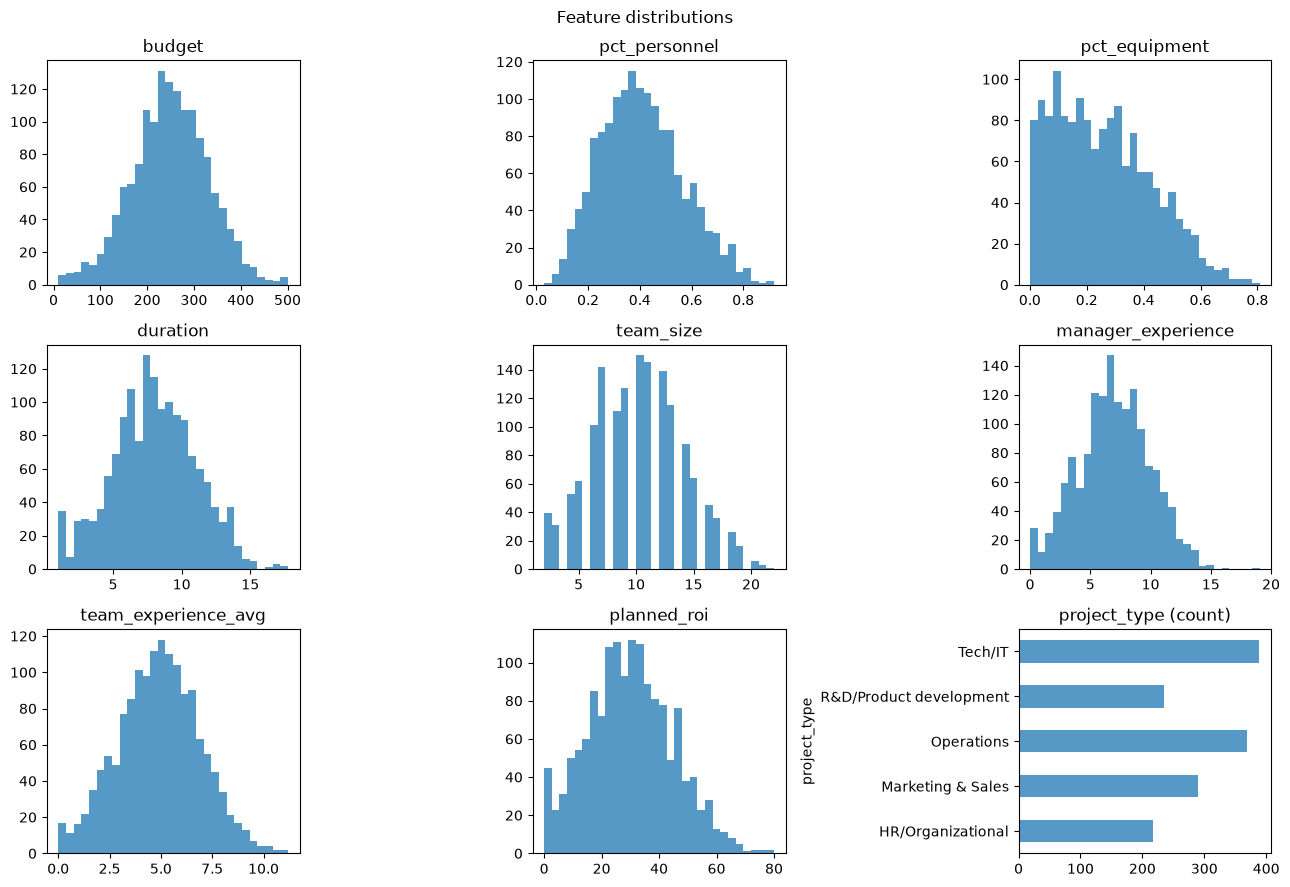

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), NUMERIC_FEATURES):
    ax.hist(df[col], bins=30, color="tab:blue", alpha=0.75)
    ax.set_title(col)
df["project_type"].value_counts().sort_index().plot.barh(ax=axes.ravel()[-1], color="tab:blue", alpha=0.75)
axes.ravel()[-1].set_title("project_type (count)")
fig.suptitle("Feature distributions")
fig.tight_layout()
plt.show()

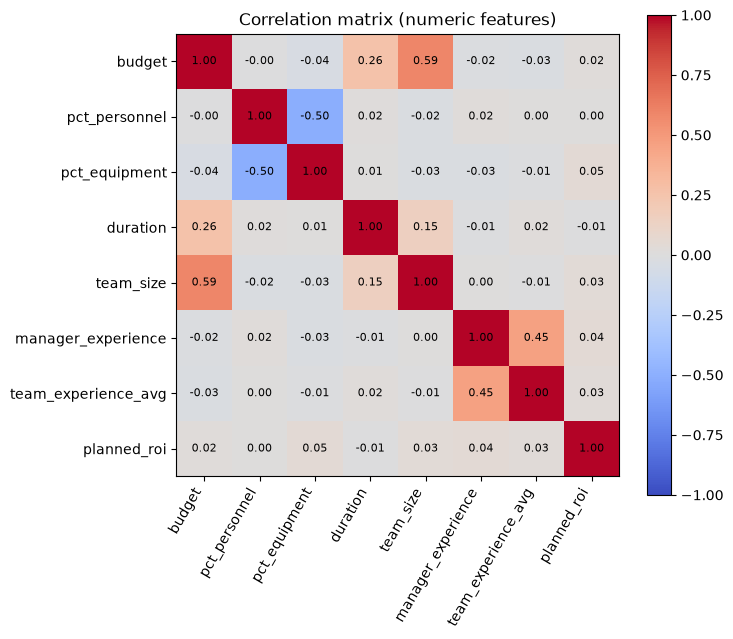

In [5]:
corr = df[NUMERIC_FEATURES].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.set_title("Correlation matrix (numeric features)")
fig.tight_layout()
plt.show()

The correlations are the ones built into the simulation (budget with duration and team size, manager experience with team experience).
Correlated predictors matter later: Naive Bayes assumes independence and is the model most affected.

,rate,n,ci95
project_type,,,
HR/Organizational,0.387,217,0.065
Marketing & Sales,0.345,290,0.055
Operations,0.352,369,0.049
R&D/Product development,0.311,235,0.059
Tech/IT,0.362,389,0.048


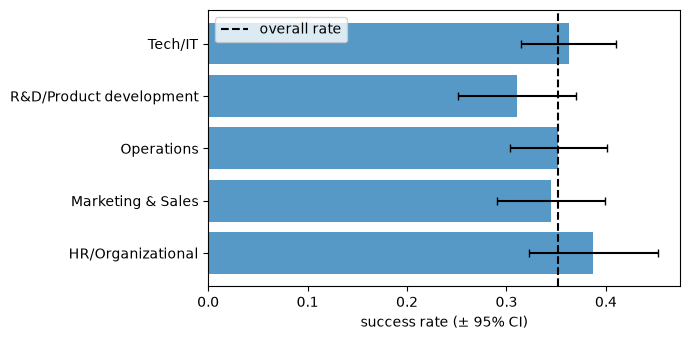

In [6]:
g = df.groupby("project_type")[TARGET].agg(rate="mean", n="count")
g["ci95"] = 1.96 * np.sqrt(g["rate"] * (1 - g["rate"]) / g["n"])
display(g.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(g.index, g["rate"], xerr=g["ci95"], color="tab:blue", alpha=0.75, capsize=3)
ax.axvline(df[TARGET].mean(), color="k", ls="--", label="overall rate")
ax.set_xlabel("success rate (± 95% CI)")
ax.legend()
fig.tight_layout()
plt.show()

Success rates differ only slightly between project types and the confidence intervals overlap.
This is expected: the type effects in the simulation are small (±0.2 / 0.3 on the logit scale), so with a few hundred projects per type they are hard to separate from sampling noise.

In [7]:
rows = {}
for col in ["budget", "duration", "manager_experience"]:
    q = pd.qcut(df[col], 4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
    rows[col] = df.groupby(q, observed=True)[TARGET].mean()
pd.DataFrame(rows).T.round(3)

,Q1 (low),Q2,Q3,Q4 (high)
budget,0.224,0.312,0.373,0.499
duration,0.445,0.365,0.315,0.283
manager_experience,0.147,0.264,0.400,0.597


Sanity check on direction: success rate rises with budget and manager experience and falls with duration, as designed.
(Marginal rates are blurred by the correlations between features and by the latent noise term.)

## 2. Model comparison

- Stratified 80/20 train/test split; 5-fold stratified cross-validation **on the training set only**
- Models: Naive Bayes, Logistic Regression, Random Forest, XGBoost, SVM (RBF)
- Reference rows: constant baseline (always predicts the base rate) and **oracle** (true probabilities from the simulation = theoretical ceiling)

In [8]:
from sklearn.model_selection import train_test_split

X, y = df[FEATURES], df[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=ev.TEST_SIZE, stratify=y, random_state=ev.SEED)

true_p = ev.oracle_probabilities(df)
fitted, test_probs, table = ev.evaluate_models(
    get_models(ev.SEED), X_tr, X_te, y_tr, y_te,
    true_p_test=None if true_p is None else true_p.loc[y_te.index])

cols = ["CV ROC-AUC", "Test ROC-AUC", "Test PR-AUC", "Test F1", "Test Accuracy", "Test Brier"]
tbl = table[cols].copy()
for c in cols[1:]:
    tbl[c] = tbl[c].astype(float).round(3)
tbl

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Test F1,Test Accuracy,Test Brier
Naive Bayes,0.780 ± 0.019,0.780,0.697,0.614,0.757,0.175
Logistic Regression,0.810 ± 0.017,0.823,0.748,0.649,0.777,0.158
Random Forest,0.783 ± 0.025,0.813,0.710,0.621,0.777,0.168
XGBoost,0.777 ± 0.017,0.802,0.704,0.611,0.750,0.173
SVM (RBF),0.795 ± 0.019,0.811,0.716,0.593,0.753,0.166
Baseline (constant),-,0.500,0.353,0.000,0.647,0.228
Oracle (true prob.),-,0.857,0.772,0.677,0.783,0.145


How to read it:
- **ROC-AUC / PR-AUC:** ranking quality of the predicted probabilities (threshold-free). PR-AUC is compared with the base rate (~0.35), not with 0.5.
- **F1 / accuracy:** computed at a fixed 0.5 threshold, not tuned.
- **Brier score:** mean squared error of the probabilities (lower is better; constant baseline is the reference).
- **CV ± std:** differences between models that are smaller than this spread should not be treated as real.

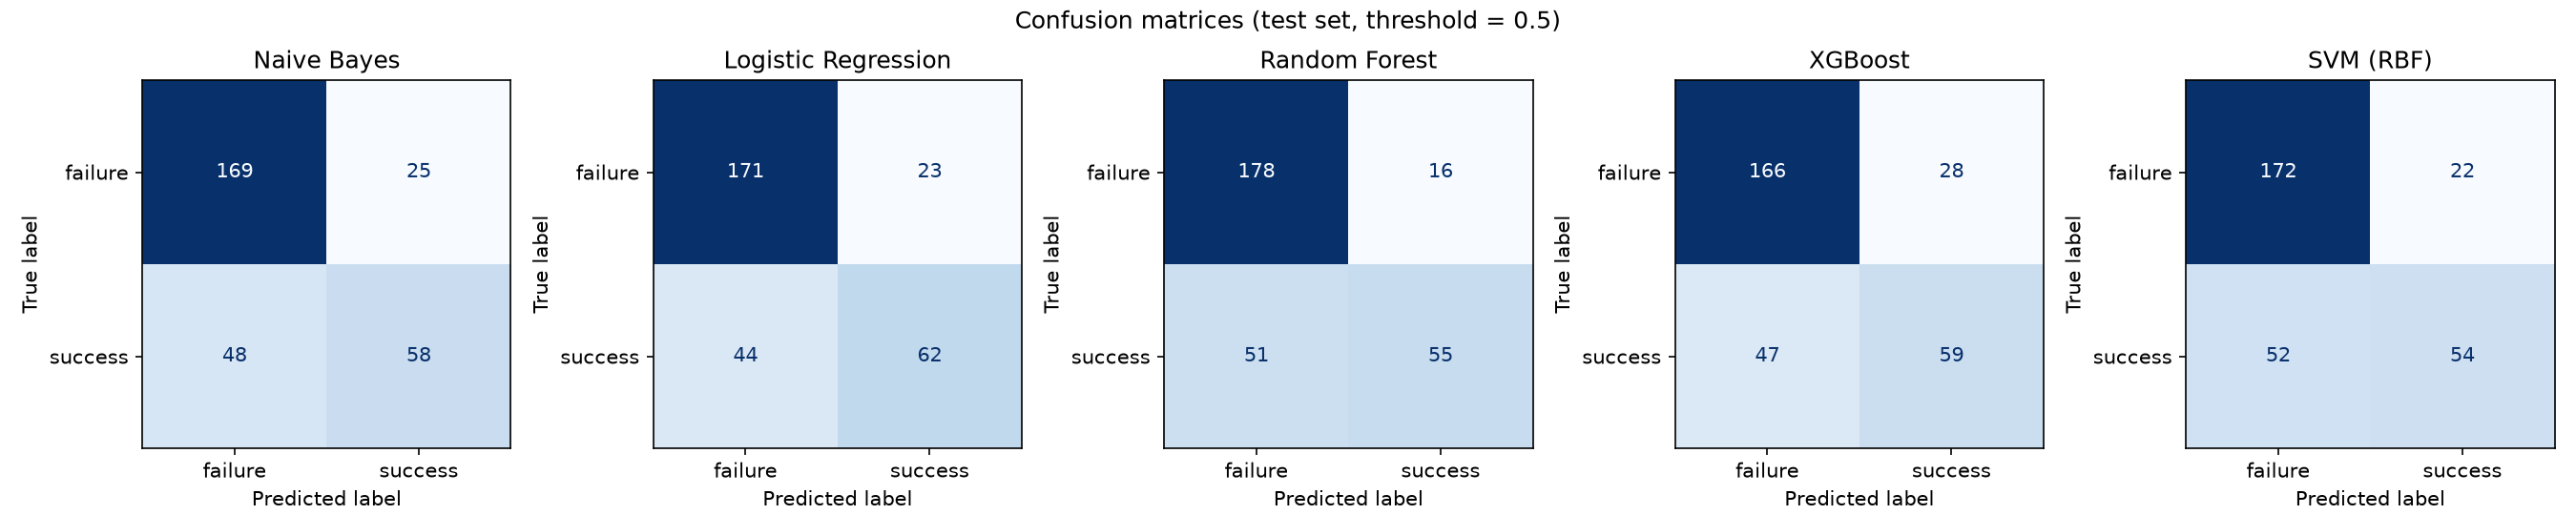

In [9]:
ev.plot_confusion_matrices(test_probs, y_te)
display(Image(filename=str(ev.FIG_DIR / "confusion_matrices.png")))

### Calibration
Curves use 5-fold *out-of-fold* predictions on all 1,500 projects (the 300-row test set would give very noisy bins).
A point on the diagonal means "when the model says 40%, about 40% of those projects succeed".

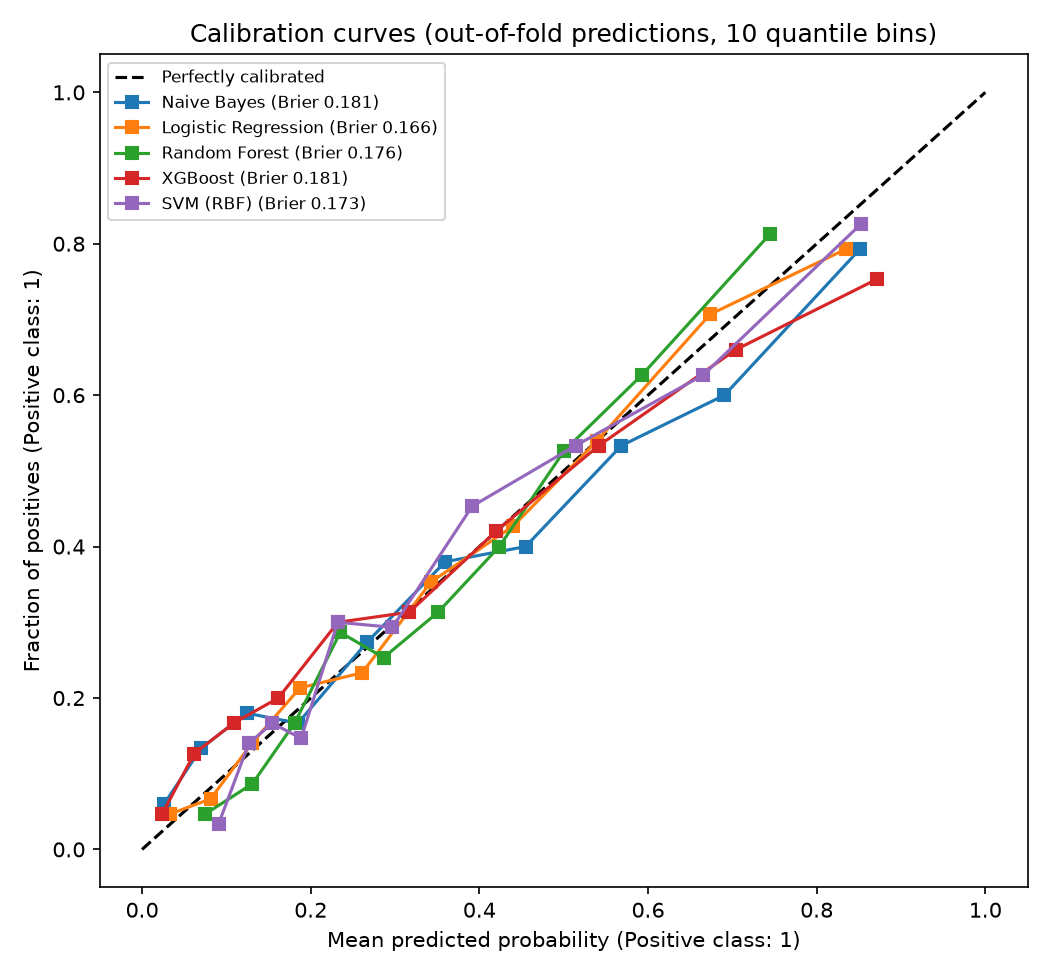

,OOF Brier
Naive Bayes,0.181
Logistic Regression,0.166
Random Forest,0.176
XGBoost,0.181
SVM (RBF),0.173


In [10]:
oof_brier = ev.plot_calibration(get_models(ev.SEED), X, y)
display(Image(filename=str(ev.FIG_DIR / "calibration.png"), width=620))
oof_brier.round(3).to_frame()

## 3. Feature importance vs true simulation weights

- **Permutation importance** (all models): drop in test ROC-AUC when a feature is shuffled; `project_type` is shuffled as one feature.
- **SHAP** (XGBoost): mean |SHAP| per feature, one-hot dummies summed back into `project_type`.
- Importances are normalised to shares so they can be compared with the true weights. The units differ (AUC drop vs logit effect), so compare **ranks and relative size, not absolute values**.

In [11]:
imp = ev.permutation_table(fitted, X_te, y_te)
imp["XGBoost (SHAP)"] = ev.shap_xgboost(fitted["XGBoost"], X_te)
true_imp = ev.true_importance()
rhos = ev.plot_importance_vs_true(imp, true_imp)

shares = imp.clip(lower=0)
shares = shares / shares.sum()
shares["TRUE"] = true_imp / true_imp.sum()
display(shares.round(3))
rhos.round(2).to_frame()

,Naive Bayes,Logistic Regression,Random Forest,XGBoost,SVM (RBF),XGBoost (SHAP),TRUE
budget,0.224,0.384,0.287,0.354,0.335,0.235,0.255
pct_personnel,0.000,0.000,0.000,0.016,0.018,0.043,0.025
pct_equipment,0.000,0.008,0.017,0.024,0.029,0.039,0.025
duration,0.088,0.173,0.151,0.150,0.174,0.169,0.153
team_size,0.016,0.010,0.007,0.019,0.013,0.047,0.076
manager_experience,0.443,0.290,0.390,0.306,0.292,0.241,0.204
team_experience_avg,0.226,0.122,0.140,0.127,0.124,0.170,0.178
planned_roi,0.002,0.002,0.009,0.004,0.003,0.038,0.038
project_type,0.000,0.010,0.000,0.000,0.014,0.018,0.045


,Spearman rho vs true
Naive Bayes,0.90
Logistic Regression,0.94
Random Forest,0.77
XGBoost,0.77
SVM (RBF),0.71
XGBoost (SHAP),0.83


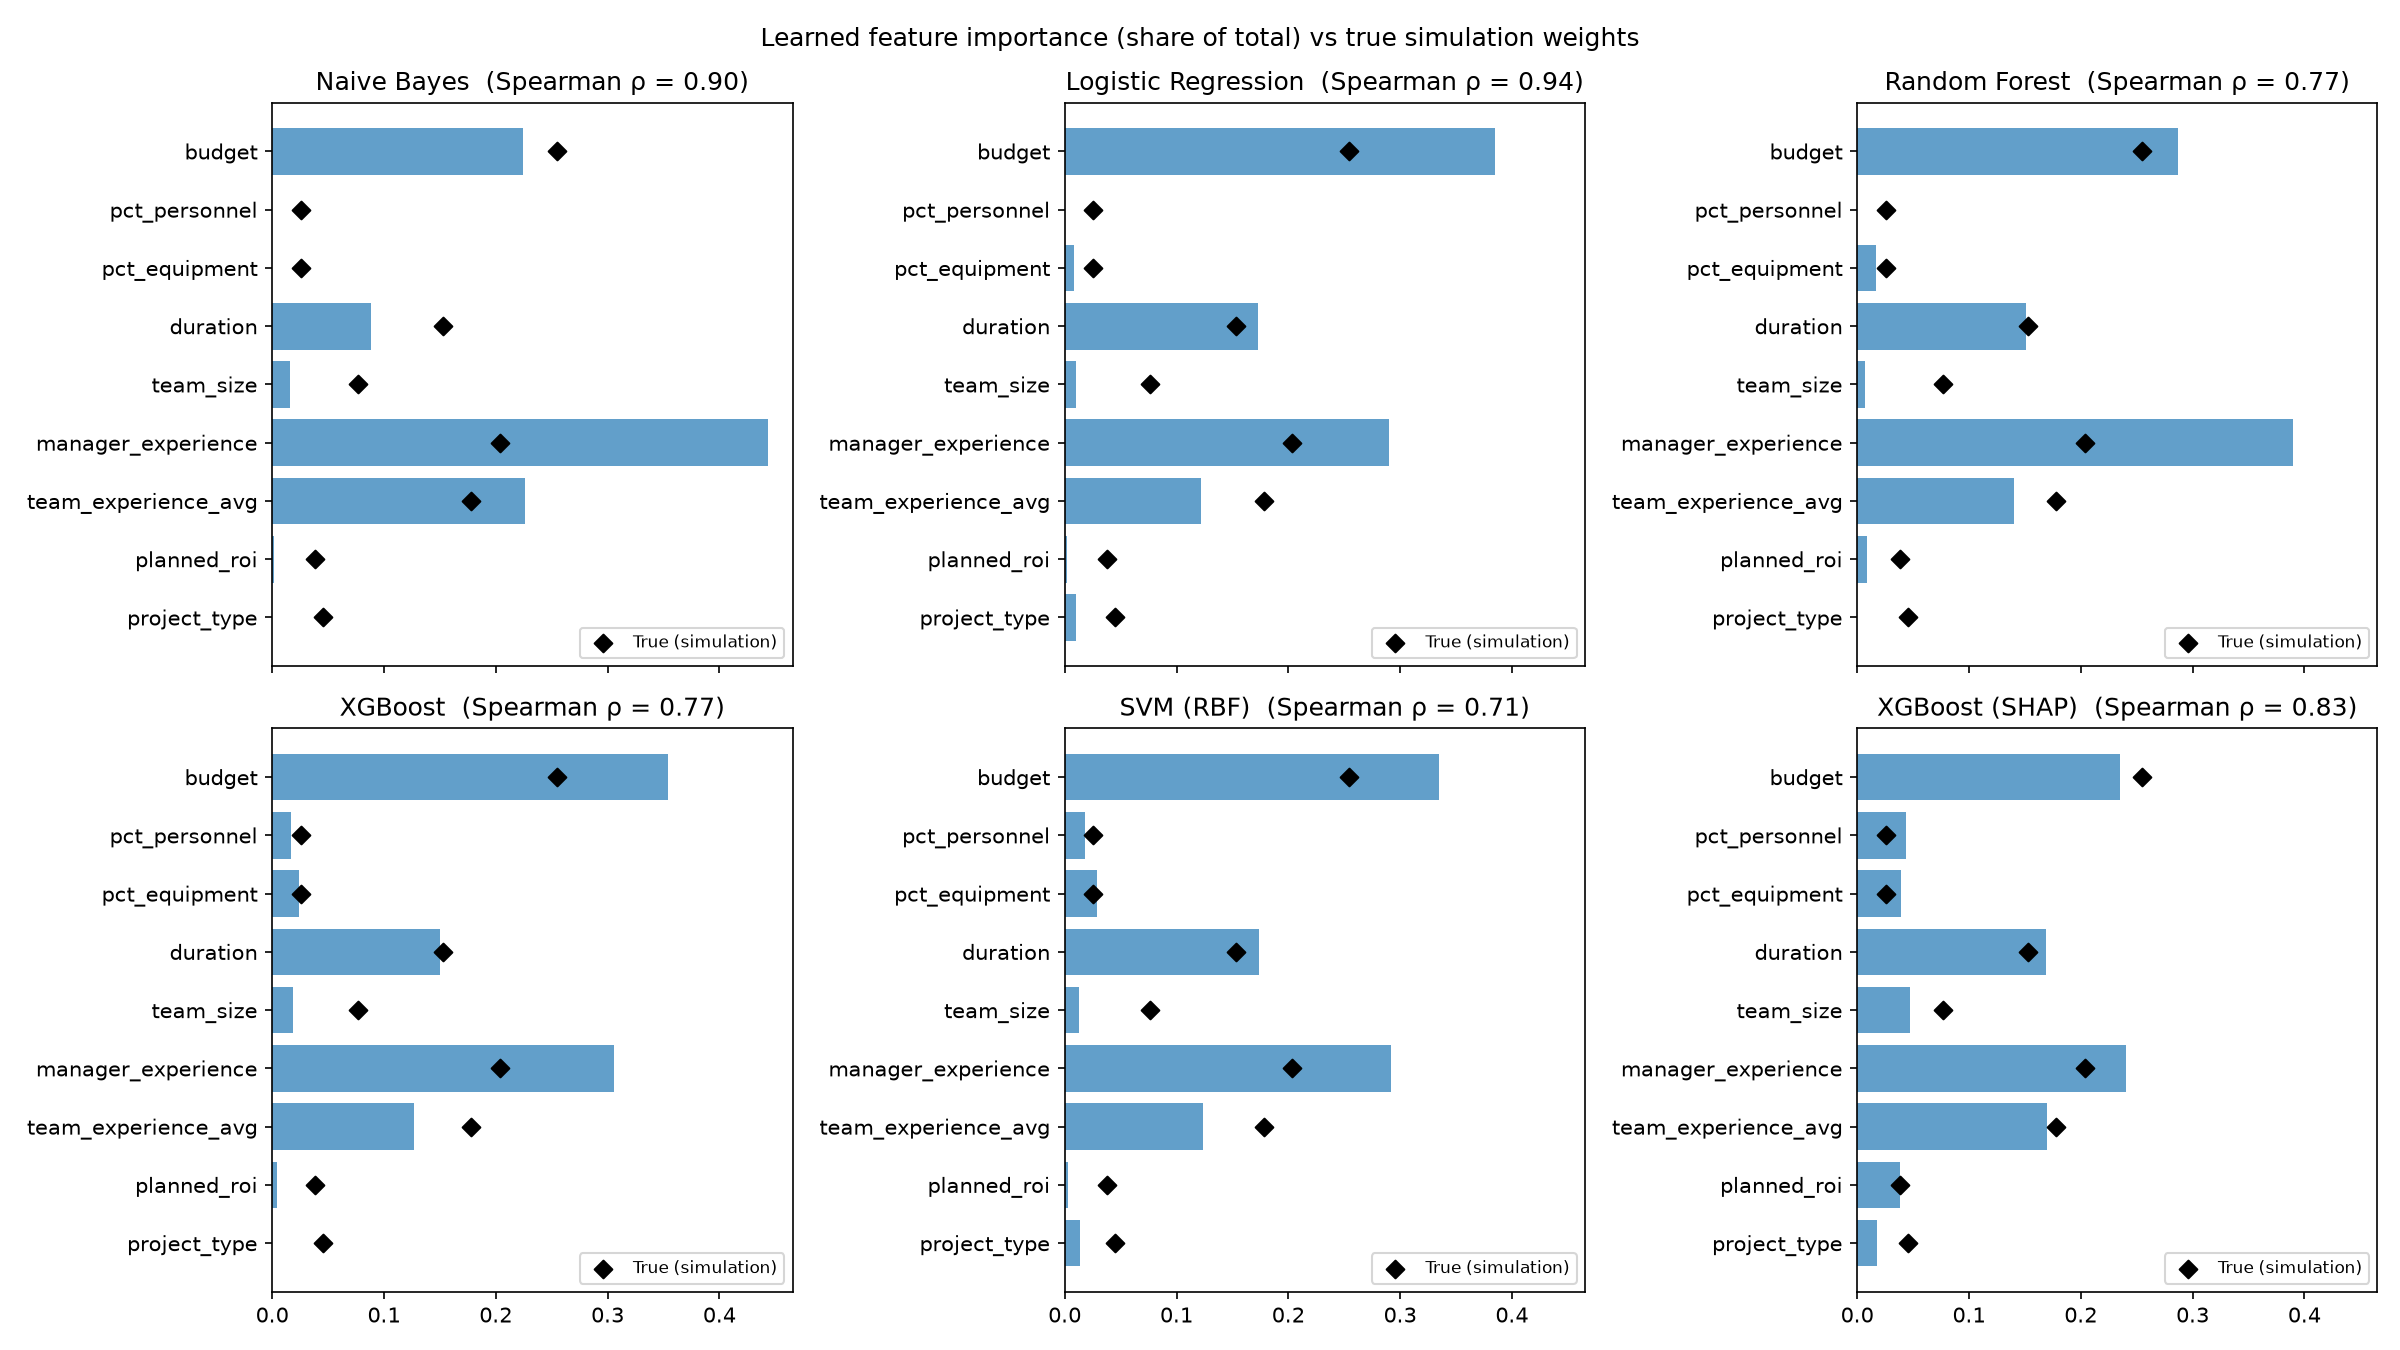

In [12]:
display(Image(filename=str(ev.FIG_DIR / "importance_vs_true.png")))

### Logistic Regression coefficients vs true weights
Features are standardised, so coefficients are directly on the scale of the simulation weights (logit change per +1 SD).
`team_size` has a true *linear* weight of 0 because its true effect is an inverted U (quadratic).

In [13]:
ev.lr_coefficients_vs_true(fitted["Logistic Regression"]).round(2)

,LR coef (per SD),True weight
budget,0.97,1.00
pct_personnel,0.06,0.10
pct_equipment,-0.18,-0.10
duration,-0.60,-0.60
team_size,-0.17,0.00
manager_experience,0.80,0.80
team_experience_avg,0.55,0.70
planned_roi,0.09,0.15


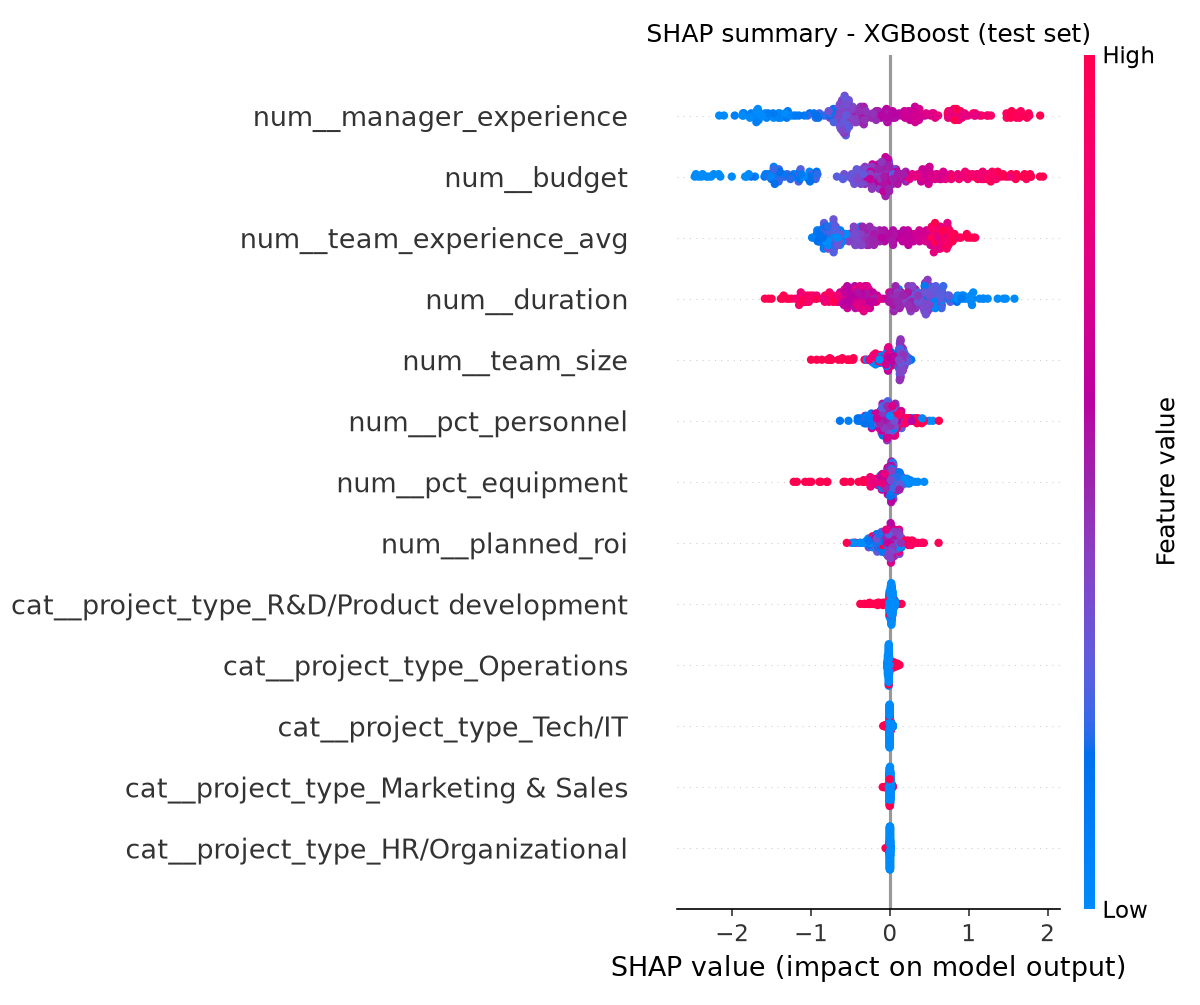

In [14]:
display(Image(filename=str(ev.FIG_DIR / "shap_summary_xgboost.png"), width=700))

## 4. Conclusions and limitations

**Conclusions**
- All five models are far better than the constant baseline and below the oracle ceiling; they separate successes from failures reasonably well but cannot reach the oracle because of the latent noise built into the simulation.
- Logistic Regression is the best or tied-best model on every headline metric, with the best Brier score. This is plausible: the true process is mostly linear on the logit scale, so a flexible model has little extra signal to exploit.
- The differences between models are small compared with the cross-validation spread. No model should be called a clear winner.
- Logistic Regression recovers the large true weights almost exactly (budget, manager experience, duration), and its importance ranking is closest to the truth.
- All models are reasonably calibrated. Some deviations appear at the extremes (e.g. Random Forest never predicts very high probabilities, Naive Bayes and XGBoost are slightly over-confident at the top), but with ~150 projects per bin the curves are noisy and should not be over-interpreted.
- Naive Bayes inflates the importance of manager experience: it counts correlated predictors (manager and team experience) as if they were independent.

**Limitations**
- **Simulated data:** results show how methods behave when the generating process is known; they say nothing about real project portfolios.
- **Small effects are not recovered:** planned ROI, project type, budget shares and team size have importance close to zero for most models. With 1,500 rows and weights of ±0.1-0.3 they are hard to detect; this is a sample-size limit, not a bug.
- **Non-linearities are only weakly captured:** the inverted-U for team size and the duration × manager-experience interaction are too small to be learned reliably by flexible models.
- **Single dataset, single seed, single split:** importances and rank correlations are unstable (they move between library versions); nothing was repeated over multiple simulations.
- **No hyperparameter tuning:** models use sensible fixed settings.
- **Fixed 0.5 threshold:** F1 and accuracy depend on it; tuning it on the test set would be leakage.
- **Different units:** permutation importance and SHAP are not on the same scale as the true logit weights, so only ranks and relative sizes are compared.

**Possible extensions:** repeat the study over many simulated datasets and sample sizes, tune hyperparameters with nested CV, tune the decision threshold with cross-validation, and test robustness to changes in the true weights.